# RiceShift
## NASA-Powered Rotation Advisor for California Rice Farms

**NASA Space Apps Challenge 2026 — Field Shift: Adapting Farms with NASA Data**  
**Team Hachi**

RiceShift is a decision-support prototype for California rice agriculture.

Its purpose is not to predict a single universally "best" crop rotation. Instead, it combines **historical crop management**, **NASA-observed environmental conditions**, **soil context**, and **agricultural outcomes** to help identify when different rotation strategies may deserve consideration.

### Candidate strategies

- **Continuous Rice**
- **Rice → Winter Vetch → Rice**
- **Rice → Winter Cover Crop Mix → Rice**

> **Hackathon question:** How can NASA Earth observations help make crop-rotation decisions more context-aware under changing environmental conditions?


# From Challenge Objective to This Colab

The **Field Shift** challenge asks for a decision-support approach that combines Earth observations with local agricultural information.

This notebook converts that objective into four evidence questions:

| Challenge need | RiceShift question | Evidence used | Colab output |
|---|---|---|---|
| Understand field history | Where has rice persisted, and where have rotations occurred? | USDA CDL | GIS map + 19-year crop history |
| Understand environmental conditions | How different are winter and rice-season moisture conditions? | NASA SMAP + MODIS | Seasonal environmental comparison |
| Connect environment to outcomes | Are NASA-observed conditions associated with rice yield? | NASA SMAP / MODIS + USDA NASS | Exploratory yield relationship |
| Support a management decision | Which strategies should remain candidates under the observed context? | Combined evidence | Strategy comparison |

## Decision-support logic

```text
Historical crop management
        ↓
NASA-observed environmental conditions
        ↓
Soil and agricultural context
        ↓
Observed rice outcomes
        ↓
Context-aware strategy comparison
```

The analysis is **exploratory and non-causal**. It is designed to organize evidence for a management decision, not to replace field trials or grower expertise.


## 30-second demonstration path

For the submission video, the notebook can be shown in this order:

**Objective → GIS map → Crop history → NASA SMAP → NASA-to-yield relationship → Strategy comparison**

The main figures below are intentionally presentation-ready so that the notebook itself can serve as the demonstration.


# 1. Load the compact analysis bundle

The full Steps 20–30 preparation workflow is preserved in the repository, but it does **not** need to be rerun for this demonstration.

The required analysis-ready outputs are already packaged in `data.zip`.

### Run in Google Colab

1. Open this notebook in Colab.
2. Open the **Files** panel on the left.
3. Drag `data.zip` into the Colab runtime.
4. Confirm that it appears as `/content/data.zip`.
5. Run the notebook from top to bottom.

Expected ZIP structure:

```text
data.zip
├── step24/
├── step25/
├── step27/
├── step28/
├── step29/
└── step30/
```

**Google Drive is not required.**


In [4]:
!wget -q --show-progress \
  -O /content/data.zip \
  https://raw.githubusercontent.com/takeofuture/riceshift/main/data.zip

/content/data.zip   100%[===================>]  25.90M   126MB/s    in 0.2s    


In [5]:
from pathlib import Path
import shutil
import zipfile
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Rasterio is used only for the GIS visualization.
try:
    import rasterio
    from rasterio.vrt import WarpedVRT
    from rasterio.enums import Resampling
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "rasterio"])
    import rasterio
    from rasterio.vrt import WarpedVRT
    from rasterio.enums import Resampling

ZIP_PATH = Path("/content/data.zip")
DATA_ROOT = Path("/content/riceshift_data")

if not ZIP_PATH.exists():
    raise FileNotFoundError(
        "data.zip was not found at /content/data.zip.\n"
        "Upload data.zip from the Colab Files panel, then run this cell again."
    )

if DATA_ROOT.exists():
    shutil.rmtree(DATA_ROOT)

DATA_ROOT.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(DATA_ROOT)

expected_steps = ["step24", "step25", "step27", "step28", "step29", "step30"]
missing = [step for step in expected_steps if not (DATA_ROOT / step).exists()]

if missing:
    raise RuntimeError(
        "Missing expected folders in data.zip: " + ", ".join(missing)
    )

print("RiceShift bundle ready.")
print("Data root:", DATA_ROOT)
print("Folders  :", ", ".join(sorted(p.name for p in DATA_ROOT.iterdir())))


RiceShift bundle ready.
Data root: /content/riceshift_data
Folders  : step24, step25, step27, step28, step29, step30


# 2. Load analysis-ready data

The compact bundle contains the outputs needed for the demonstration:

- **Step 24** — MODIS / CDL analysis-ready environmental features
- **Step 25** — USDA NASS rice outcomes joined to environmental features
- **Step 27** — NASA SMAP soil-moisture features
- **Step 28** — CDL crop-history summaries and GeoTIFF rasters
- **Step 29** — SSURGO soil properties
- **Step 30** — final data-coverage checks


In [6]:
# Step 24
monthly = pd.read_parquet(DATA_ROOT / "step24/monthly_features.parquet")
seasonal = pd.read_parquet(DATA_ROOT / "step24/seasonal_features.parquet")
winter = pd.read_parquet(DATA_ROOT / "step24/winter_cover_features.parquet")
full_year = pd.read_parquet(DATA_ROOT / "step24/full_year_features.parquet")

# Step 25
nass = pd.read_parquet(DATA_ROOT / "step25/model_yearly.parquet")

# Step 27
smap_daily = pd.read_parquet(DATA_ROOT / "step27/smap_daily.parquet")
smap_monthly = pd.read_parquet(DATA_ROOT / "step27/smap_monthly.parquet")
smap_seasonal = pd.read_parquet(DATA_ROOT / "step27/smap_seasonal.parquet")
smap_annual = pd.read_parquet(DATA_ROOT / "step27/smap_annual.parquet")

# Step 28
rotation = pd.read_csv(DATA_ROOT / "step28/yearly_group_counts.csv")
rotation_summary = pd.read_csv(DATA_ROOT / "step28/rotation_class_summary.csv")

# Step 29
soil = pd.read_parquet(DATA_ROOT / "step29/ssurgo_mapunit_top30cm.parquet")

summary = pd.DataFrame({
    "Dataset": [
        "MODIS/CDL monthly",
        "MODIS/CDL seasonal",
        "Winter features",
        "NASS yearly",
        "SMAP daily",
        "SMAP seasonal",
        "CDL crop history",
        "SSURGO soil"
    ],
    "Rows": [
        len(monthly),
        len(seasonal),
        len(winter),
        len(nass),
        len(smap_daily),
        len(smap_seasonal),
        len(rotation),
        len(soil)
    ]
})

display(summary)


,Dataset,Rows
0,MODIS/CDL monthly,228
1,MODIS/CDL seasonal,19
2,Winter features,18
3,NASS yearly,19
4,SMAP daily,3820
5,SMAP seasonal,21
6,CDL crop history,19
7,SSURGO soil,4977


# 3. GIS View — Where Has Rice Persisted?

## Why this matters

A rotation recommendation should start with **management history and location**, not only with a statewide average.

The CDL-based raster below counts how many years each pixel was classified as rice from **2007–2025**.

- A high value indicates persistent rice cultivation.
- A lower value indicates less persistent rice use or more frequent transitions to other land-cover classes.

This provides the spatial foundation for RiceShift before adding NASA environmental observations.


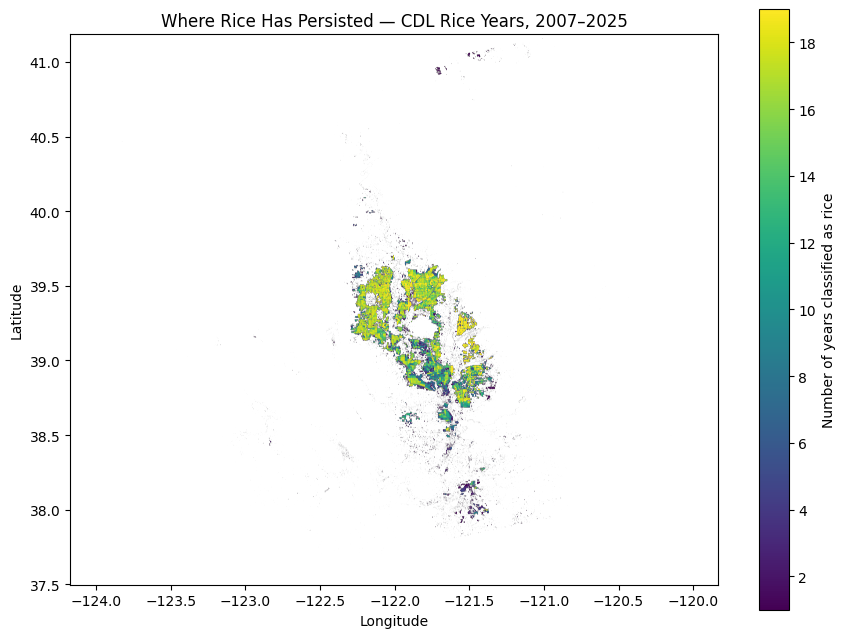

In [7]:
rice_year_tif = DATA_ROOT / "step28/raster/rice_year_count.tif"

with rasterio.open(rice_year_tif) as src:
    # Reproject on the fly to geographic coordinates for an intuitive map.
    with WarpedVRT(
        src,
        crs="EPSG:4326",
        resampling=Resampling.nearest
    ) as vrt:
        rice_years = vrt.read(1, masked=True)
        b = vrt.bounds

fig, ax = plt.subplots(figsize=(9, 8))
img = ax.imshow(
    rice_years,
    extent=[b.left, b.right, b.bottom, b.top],
    origin="upper"
)

ax.set_title("Where Rice Has Persisted — CDL Rice Years, 2007–2025")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

cbar = fig.colorbar(img, ax=ax, shrink=0.78)
cbar.set_label("Number of years classified as rice")

plt.tight_layout()
plt.show()


### What this shows

RiceShift is not starting from an abstract statewide recommendation.

It first identifies **where long-term rice cultivation has actually occurred**. That historical pattern becomes the first layer in the decision-support logic:

> **Field history → environmental conditions → outcome evidence → strategy candidate**


# 4. Experiment 1 — 19-Year Crop-History Context

## Objective link

The challenge asks how farms can adapt. Adaptation decisions depend partly on what the agricultural landscape has already been doing.

USDA CDL provides a consistent annual record of rice and other crop groups from **2007–2025**.

This figure answers:

> **How stable has rice been relative to fallow and alternative crop groups over time?**


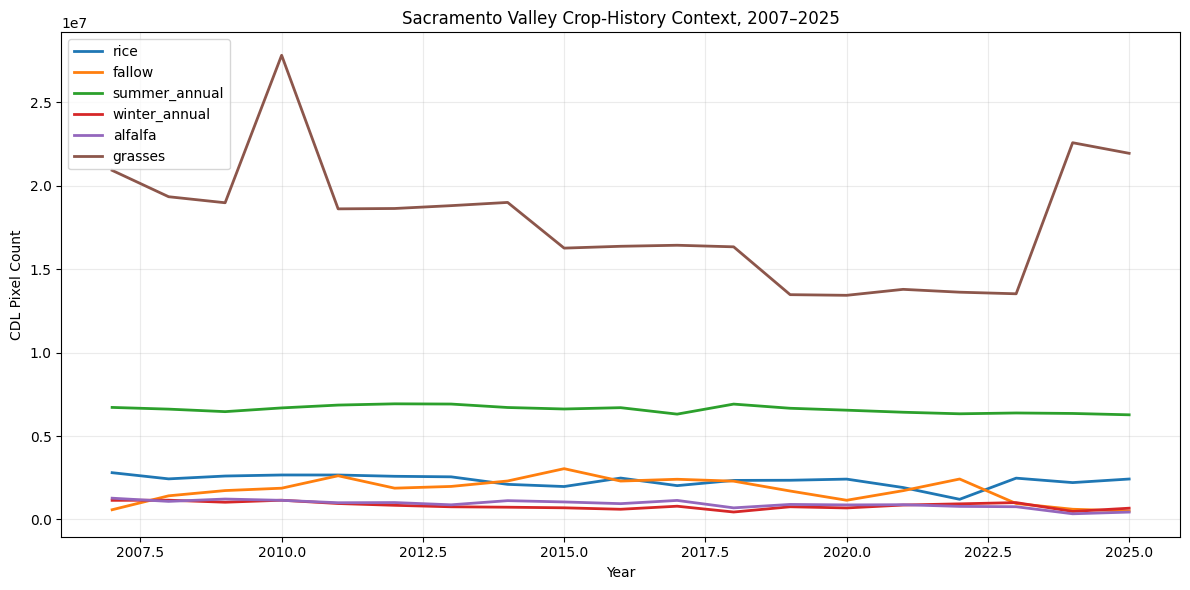

In [8]:
crop_cols = [
    "rice",
    "fallow",
    "summer_annual",
    "winter_annual",
    "alfalfa",
    "grasses",
]

ax = rotation.set_index("year")[crop_cols].plot(
    figsize=(12, 6),
    linewidth=2
)

ax.set_title("Sacramento Valley Crop-History Context, 2007–2025")
ax.set_xlabel("Year")
ax.set_ylabel("CDL Pixel Count")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


### What this adds to the decision

The crop-history time series describes the **management context** surrounding rice.

RiceShift uses this information to avoid treating every rice-growing location as identical. Long-term persistence, fallow history, and alternative crop presence provide context for whether a rotation strategy is even plausible before environmental suitability is considered.


# 5. Experiment 2 — NASA SMAP: Winter vs. Rice Season

## Objective link

Historical crop maps tell us **what happened**, but not the physical conditions under which management decisions occurred.

NASA SMAP adds an environmental layer by measuring surface soil moisture.

RiceShift separates the year into:

- **Rice season:** April–November
- **Winter cover-crop window:** previous November through March

This comparison asks:

> **Are winter conditions materially different from the rice-growing season, and therefore worth evaluating separately when considering a winter rotation?**


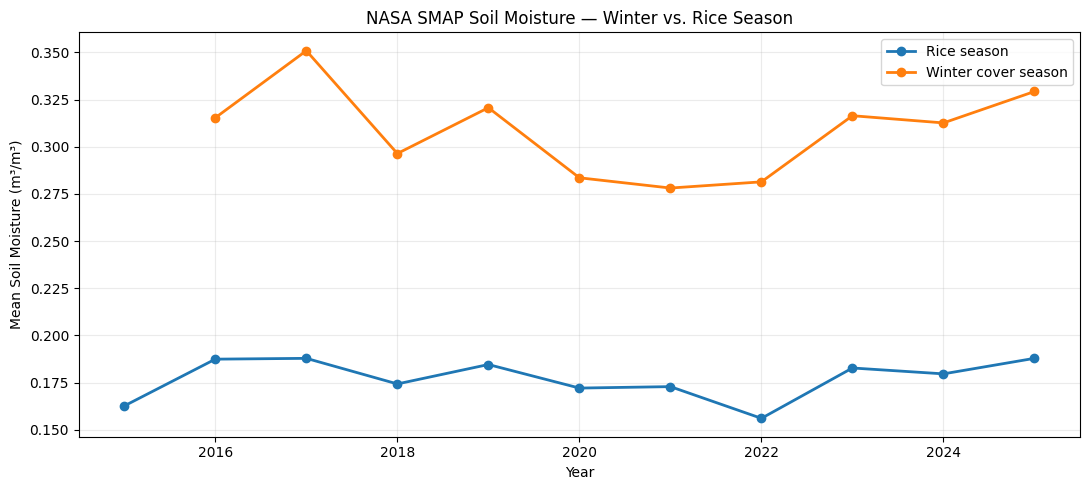

In [9]:
rice_smap = (
    smap_seasonal.loc[
        smap_seasonal["season"] == "rice_apr_nov",
        ["year", "soil_moisture_mean"]
    ]
    .rename(columns={"soil_moisture_mean": "Rice season"})
)

winter_smap = (
    smap_seasonal.loc[
        smap_seasonal["season"] == "winter_cover_nov_mar",
        ["year", "soil_moisture_mean"]
    ]
    .rename(columns={"soil_moisture_mean": "Winter cover season"})
)

smap_compare = (
    rice_smap
    .merge(winter_smap, on="year", how="outer")
    .sort_values("year")
)

ax = smap_compare.set_index("year").plot(
    figsize=(11, 5),
    marker="o",
    linewidth=2
)

ax.set_title("NASA SMAP Soil Moisture — Winter vs. Rice Season")
ax.set_xlabel("Year")
ax.set_ylabel("Mean Soil Moisture (m³/m³)")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


### What this adds to the decision

A winter rotation should not be evaluated only from summer rice conditions.

NASA SMAP allows RiceShift to treat the **winter management window as its own environmental decision period**. This is the main NASA contribution to the rotation-screening logic in the current prototype.


# 6. Experiment 3 — NASA Conditions and Agricultural Outcomes

## Objective link

The challenge is not only about observing environmental change. The observations need to be connected to an agricultural decision.

RiceShift therefore combines:

- NASA SMAP soil moisture
- MODIS-derived seasonal indicators
- USDA NASS rice yield

The common complete winter-to-rice SMAP comparison period is **2016–2025**.

Because this is a short observational time series, the analysis remains deliberately simple and transparent.


In [10]:
rice_env = nass[
    [
        "year",
        "ndvi",
        "evi",
        "lai",
        "et",
        "pet",
        "lst_day_c",
        "nass_yield_lb_acre",
        "nass_harvested_acres",
    ]
].copy()

rice_env = rice_env.rename(columns={
    "ndvi": "rice_ndvi",
    "evi": "rice_evi",
    "lai": "rice_lai",
    "et": "rice_et",
    "pet": "rice_pet",
    "lst_day_c": "rice_lst_day_c",
})

winter_env = winter[
    ["year", "ndvi", "evi", "et", "lst_day_c"]
].copy()

winter_env = winter_env.rename(columns={
    "ndvi": "winter_ndvi",
    "evi": "winter_evi",
    "et": "winter_et",
    "lst_day_c": "winter_lst_day_c",
})

smap_rice = rice_smap.rename(columns={"Rice season": "smap_rice"})
smap_winter = winter_smap.rename(columns={"Winter cover season": "smap_winter"})

integrated = (
    rice_env
    .merge(winter_env, on="year", how="left")
    .merge(smap_rice, on="year", how="left")
    .merge(smap_winter, on="year", how="left")
)

submission_period = integrated.dropna(
    subset=["smap_rice", "smap_winter", "nass_yield_lb_acre"]
).copy()

print(
    f"Common complete comparison period: "
    f"{submission_period['year'].min()}–{submission_period['year'].max()} "
    f"({len(submission_period)} annual observations)"
)

display(
    submission_period[
        ["year", "smap_rice", "smap_winter", "nass_yield_lb_acre"]
    ]
)


Common complete comparison period: 2016–2025 (10 annual observations)


,year,smap_rice,smap_winter,nass_yield_lb_acre
9,2016,0.187423,0.315369,8840.0
10,2017,0.187851,0.350908,8410.0
11,2018,0.174285,0.296408,8620.0
12,2019,0.184575,0.320702,8460.0
13,2020,0.172096,0.283556,8720.0
14,2021,0.172861,0.278123,9050.0
15,2022,0.156051,0.281399,8770.0
16,2023,0.182742,0.316453,8540.0
17,2024,0.179626,0.312643,8540.0
18,2025,0.187861,0.329296,8450.0


## NASA-to-yield relationship

A scatter plot makes the decision-support link visible:

> **NASA environmental observation → observed agricultural outcome**

This does **not** establish causation. It shows whether the environmental signal is meaningfully associated with yield during the common observation period.


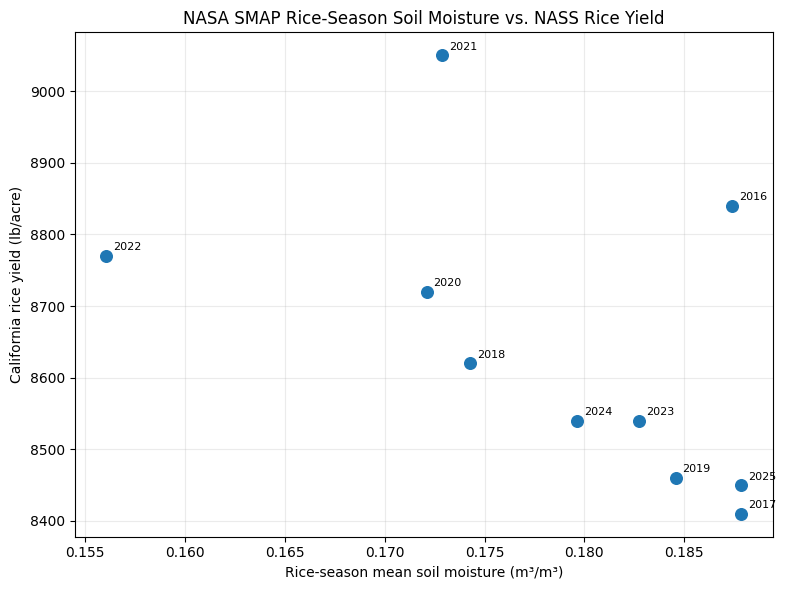

Spearman correlation: -0.669
Interpretation: exploratory association only; not evidence of causation.


In [11]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    submission_period["smap_rice"],
    submission_period["nass_yield_lb_acre"],
    s=70
)

# Add year labels so each point remains interpretable in a short demo.
for _, row in submission_period.iterrows():
    ax.annotate(
        str(int(row["year"])),
        (row["smap_rice"], row["nass_yield_lb_acre"]),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8
    )

ax.set_title("NASA SMAP Rice-Season Soil Moisture vs. NASS Rice Yield")
ax.set_xlabel("Rice-season mean soil moisture (m³/m³)")
ax.set_ylabel("California rice yield (lb/acre)")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

rho = submission_period[
    ["smap_rice", "nass_yield_lb_acre"]
].corr(method="spearman").iloc[0, 1]

print(f"Spearman correlation: {rho:.3f}")
print("Interpretation: exploratory association only; not evidence of causation.")


### What this adds to the decision

The purpose of the outcome comparison is not to build a black-box prediction model from only ten annual observations.

Instead, it provides a transparent check that NASA-observed conditions can be placed in the same analytical framework as agricultural outcomes.

That makes the final strategy comparison evidence-based rather than purely conceptual.


# 7. Supporting Context — Soil and Additional Environmental Indicators

SSURGO and MODIS provide additional context that can be used in a more operational version of RiceShift.

The compact bundle includes top-30-cm SSURGO properties such as:

- pH
- electrical conductivity
- sodium adsorption ratio
- saturated hydraulic conductivity
- sand / silt / clay fractions
- organic matter

These variables are not used here to claim a field-level prescription because the compact demonstration bundle does not include field-boundary geometry.

Instead, they show how the prototype can be extended from a regional screening framework toward field-specific agronomic validation.


In [12]:
soil_cols = [
    "ph1to1h2o_r_0_30cm",
    "ec_r_0_30cm",
    "sar_r_0_30cm",
    "ksat_r_0_30cm",
    "sandtotal_r_0_30cm",
    "silttotal_r_0_30cm",
    "claytotal_r_0_30cm",
    "om_r_0_30cm",
]

available_soil_cols = [c for c in soil_cols if c in soil.columns]

soil_summary = soil[available_soil_cols].describe().T[
    ["count", "mean", "std", "min", "50%", "max"]
]

display(soil_summary)


,count,mean,std,min,50%,max
ph1to1h2o_r_0_30cm,4801.0,6.346763,0.606927,4.500000,6.300000,10.12
ec_r_0_30cm,4891.0,0.305765,1.519716,0.000000,0.000000,30.00
sar_r_0_30cm,4885.0,0.301580,3.334874,0.000000,0.000000,96.90
ksat_r_0_30cm,4905.0,16.573200,24.494616,0.000000,9.000000,423.00
sandtotal_r_0_30cm,4821.0,44.380049,17.415513,0.956667,41.400000,98.50
silttotal_r_0_30cm,4823.0,33.423611,10.795313,0.700000,36.316667,71.80
claytotal_r_0_30cm,4850.0,22.084895,11.055051,0.000000,21.000000,65.00
om_r_0_30cm,4877.0,3.028769,4.493269,0.000000,1.800000,50.00


# 8. RiceShift Strategy Comparison

The final prototype does **not** declare one rotation universally optimal.

Instead, it keeps strategies as candidates depending on the evidence available for a location and season.

| Strategy | When it remains a candidate | Evidence used |
|---|---|---|
| **Continuous Rice** | Long rice history and current rice-season conditions remain suitable | CDL history + MODIS + SMAP + NASS |
| **Rice → Winter Vetch → Rice** | Winter rotation appears environmentally feasible and agronomic validation supports vetch | CDL rotation history + winter MODIS + winter SMAP + SSURGO context |
| **Rice → Winter Cover Crop Mix → Rice** | Winter rotation appears environmentally feasible and a diversified cover strategy is agronomically appropriate | CDL rotation history + winter MODIS + winter SMAP + SSURGO context |

### Important limitation

The current regional datasets can identify **where and when a winter-rotation strategy deserves consideration**, but they do not provide enough field-level evidence to prove that vetch or a cover-crop mix is universally superior.

That distinction is intentional: RiceShift is a **screening and decision-support prototype**, not a causal agronomic recommendation engine.


# 9. What RiceShift Demonstrates

## Challenge objective

Use NASA Earth observations together with agricultural context to support more resilient crop-rotation decisions.

## What this notebook demonstrates

1. **GIS / crop history** identifies where long-term rice cultivation has occurred.
2. **USDA CDL history** shows how the agricultural landscape has changed over 19 years.
3. **NASA SMAP** characterizes the winter and rice-season environmental windows separately.
4. **NASA + NASS integration** connects Earth-observation signals with an agricultural outcome.
5. **SSURGO context** provides a path toward future field-level screening.
6. The combined evidence is translated into a **transparent strategy comparison** rather than a black-box recommendation.

## Final interpretation

RiceShift demonstrates how NASA data can become part of a practical agricultural decision workflow:

> **Observe the field history → observe the environment → check agricultural outcomes → compare management options**

Operational use would still require field boundaries, grower priorities, economics, and agronomic validation.
